### 0. Defining constants and functions

In [49]:
using LinearAlgebra
using Plots
using Plots.Measures
using LambertW
using Distributions
using Statistics
using QuadGK
using PGFPlotsX
using LaTeXStrings

pgfplotsx()
push!(PGFPlotsX.CUSTOM_PREAMBLE, "\\usepackage{amsmath}")

# Constants for Re=2500 in the ONERA tunnel (H. Kahalerras, Y. Malécot, Y. Gagne, B. Castaing, Intermittency and Reynolds number, Phys. Fluids 10 (1998))
#c1 = 0.37

c2 = 0.025
c1 = 1/3 + 3/2 * c2
L = 0.0302    #(in m)
σ = 1.0      #(in m^2/s^2)

1.0

In [50]:
gr()

Plots.GRBackend()

In [51]:
# Function
f(h, l, x) = -log(l/L) * ((h - c1)^2 / (2*c2) - h) + 0.5 * (x/σ)^2 * (l/L)^(-2h)

# First derivative f'(h, l, x) selon h
fprime(h, l, x) = -log(l/L) * ((h - c1)/(c2) - 1 + (x/σ)^2 * (l/L)^(-2h))

# Second derivative f''(h, l, x) selon h
fsecond(h, l, x) = -log(l/L) * (1/(c2) - 2 * (x/σ)^2 * log(l/L) * (l/L)^(-2h))

fsecond (generic function with 1 method)

### 1. Normalized PDF, explicit form

In [52]:
normalization_term(l) = sqrt(σ^2 * (l/L)^(2*(c1-c2)))
#normalization_term(l) = sqrt((l/L)^(2/3))

function safe_integrand_pdf(h, l, x)
    val = exp(-f(h,l,x))
    return isfinite(val) ? val : 0.0
end

function compute_P_δlu_of_x(l, x)
    prefactor = (1 / (2π*σ)) * sqrt(-log(l/L) / c2)

    integral, err = quadgk(
        h -> safe_integrand_pdf(h,l,x),
        -Inf, Inf;
    )

    return prefactor * integral
end

function compute_P_δlv_of_x(l, x)
    return normalization_term(l) * compute_P_δlu_of_x(l, normalization_term(l)*x)
end

compute_P_δlv_of_x (generic function with 1 method)

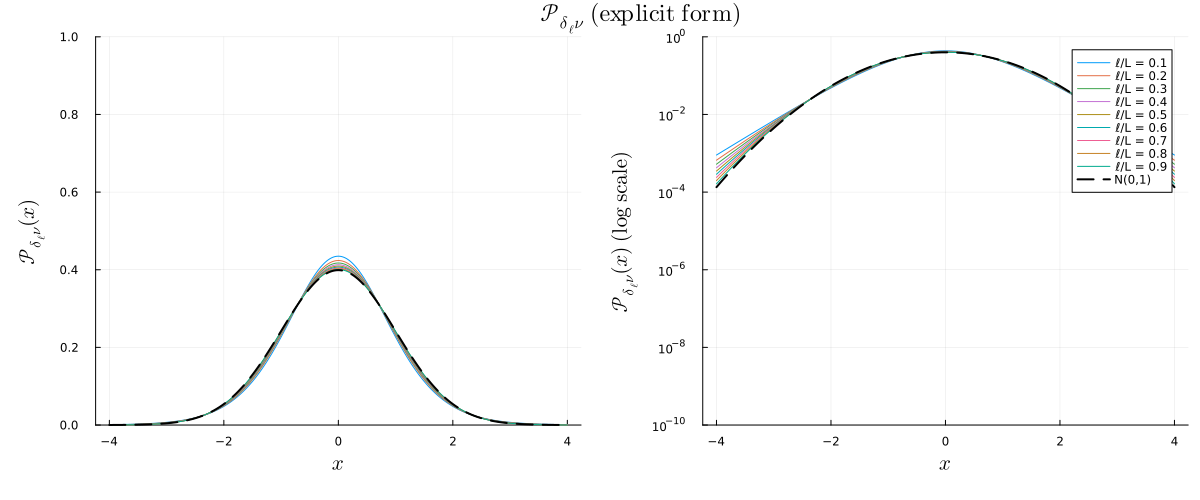

In [53]:
# Setup l and x values
l_values = 0.1*L:0.1*L:0.9*L
x_values = -4:0.02:4

y_ticks = [1e-10, 1e-8, 1e-6, 1e-4, 1e-2, 1]

# Initialize plots with explicit scales
p1 = plot(xlabel = L"x", ylabel = L"\mathcal{P}_{\delta_\ell \nu}(x)", ylims=(0, 1), legend=false, lw = 2, guidefontsize=14, left_margin = 10mm, bottom_margin = 10mm)
p2 = plot(xlabel = L"x", ylabel = L"\mathcal{P}_{\delta_\ell \nu}(x)\ \mathrm{(log\ scale)}", ylims=(1e-10, 1), yticks=y_ticks, yscale=:log10, lw = 2, guidefontsize=14, left_margin = 10mm, bottom_margin = 10mm) # Note the :log scale here

# Reference Gaussian
gauss_pdf = pdf.(Normal(0, 1), x_values)

# Plot loop
for l in l_values
    P_values = compute_P_δlv_of_x.(Ref(l), x_values)
    
    label = "ℓ/L = $(round(l/L, sigdigits=2))"
    plot!(p1, x_values, P_values, label = label)
    plot!(p2, x_values, P_values, label = label)
end

# Add Gaussian reference to both
plot!(p1, x_values, gauss_pdf, label="N(0,1)", lw=2, ls=:dash, color=:black)
plot!(p2, x_values, gauss_pdf, label="N(0,1)", lw=2, ls=:dash, color=:black)

# Final Layout
n_pdf1 = plot(p1, p2, layout = (1, 2), size = (1200, 500), plot_title = L"\mathcal{P}_{\delta_\ell \nu}\ \mathrm{(explicit\ form)}", plot_titlevspan=0.05)
savefig(n_pdf1, joinpath(@__DIR__, "..", "latex/images/normalized_figures", "n_pdf1.png"))

n_pdf1

### 2. Normalized PDF, computed using Laplace approximation with h*=c_1

In [54]:
# Value of h_star
h_star(l, x) = c1

h_star (generic function with 1 method)

In [55]:
normalization_term(l) = sqrt(σ^2 * (l/L)^(2*(c1-c2)))

function compute_P_δlu_of_x_Laplace(l, x, h_star, tol=1e-10, maxiter=100)
    # Asserts the validity of the Laplace point (f'' must be < 0)
    if fsecond(h_star(l, x), l, x) <= 0 || isnan(fsecond(h_star(l, x), l, x))
        return 0.0
    end

    prefactor = (1 / (sqrt(2π) * σ)) * sqrt((-log(l/L)) / c2) * sqrt(1 / (fsecond(h_star(l, x), l, x)))
    exponent = -f(h_star(l, x), l, x)

    exponent = clamp(exponent, -700, 700)
    return prefactor * exp(exponent)
end

"""
function compute_P_δlv_of_x_Laplace(l, x, h_star; tol=1e-10, maxiter=100)
    return normalization_term(l) * compute_P_δlu_of_x_Laplace(l, normalization_term(l)*x, h_star)
end
"""

# FIXED
function compute_P_δlv_of_x_Laplace(l, x, h_star; tol=1e-10, maxiter=100)
    # Evaluate h_star at the normalized x first
    h_star_val = h_star(l, x)
    # Then pass a frozen version (ignores its x argument) into the un-normalized function
    h_star_frozen = (l, _x) -> h_star_val
    return normalization_term(l) * compute_P_δlu_of_x_Laplace(l, normalization_term(l)*x, h_star_frozen)
end

compute_P_δlv_of_x_Laplace (generic function with 1 method)

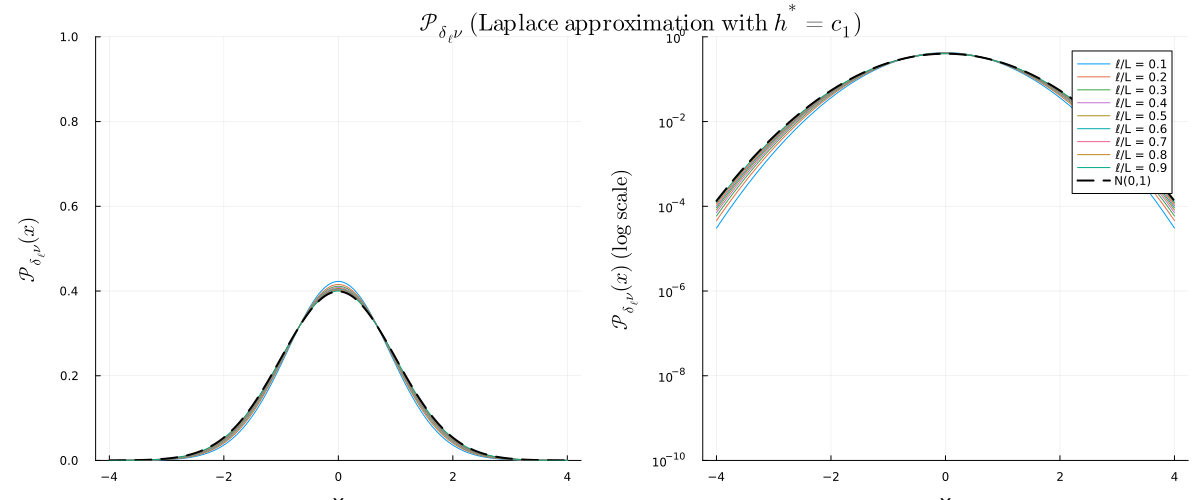

In [56]:
# Setup l and x values
l_values = 0.1*L:0.1*L:0.9*L
x_values = -4:0.02:4

y_ticks = [1e-10, 1e-8, 1e-6, 1e-4, 1e-2, 1]

# Initialize plots with explicit scales
p1 = plot(xlabel = "x", ylabel = L"\mathcal{P}_{\delta_\ell \nu}(x)", ylims=(0, 1), lw = 2, guidefontsize = 14, legend=false, left_margin = 10mm)
p2 = plot(xlabel = "x", ylabel = L"\mathcal{P}_{\delta_\ell \nu}(x)\ \mathrm{(log\ scale)}", ylims=(1e-10, 1), yticks=y_ticks, yscale=:log10, lw = 2, guidefontsize=14, left_margin = 10mm)

# Reference Gaussian
gauss_pdf = pdf.(Normal(0, 1), x_values)

# Plot loop
for l in l_values
    
    P_values = compute_P_δlv_of_x_Laplace.(Ref(l), x_values, Ref(h_star))
    
    label = "ℓ/L = $(round(l/L, sigdigits=2))"
    plot!(p1, x_values, P_values, label = label)
    plot!(p2, x_values, P_values, label = label)
end

# Add Gaussian reference to both
plot!(p1, x_values, gauss_pdf, label="N(0,1)", lw=2, ls=:dash, color=:black)
plot!(p2, x_values, gauss_pdf, label="N(0,1)", lw=2, ls=:dash, color=:black)

# Final Layout
n_pdf2 = plot(p1, p2, layout = (1, 2), size = (1200, 500), plot_title = L"\mathcal{P}_{\delta_\ell \nu}\ \mathrm{(Laplace\ approximation\ with\ }h^{*}=c_{1}\mathrm{)}", plot_titlevspan=0.05)
savefig(n_pdf2, joinpath(@__DIR__, "..", "latex/images/normalized_figures", "n_pdf2.png"))

n_pdf2

### 3. Normalized PDF, computed using Laplace approximation with h* from Lambert W

In [57]:
# Value of h_star
h_star2(l, x) = c1 + c2 - lambertw(2 * (-log(l / L)) * c2 * x^2 * exp(4 * (-log(l/L)) * c2)) / (2 * -log(l / L))

h_star2 (generic function with 1 method)

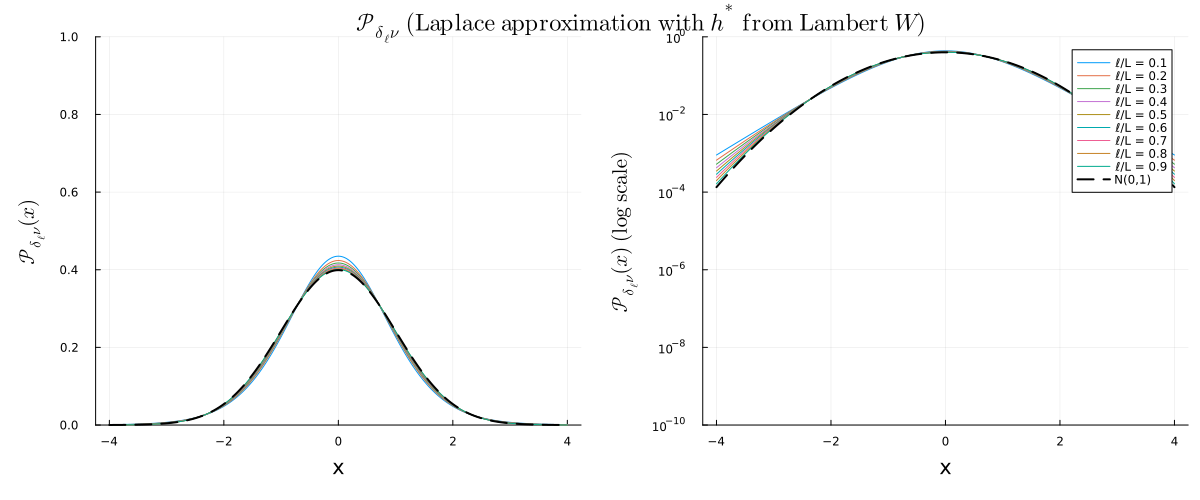

In [58]:
# Setup l and x values
l_values = 0.1*L:0.1*L:0.9*L
x_values = -4:0.02:4

y_ticks = [1e-10, 1e-8, 1e-6, 1e-4, 1e-2, 1]

# Initialize plots with explicit scales
p1 = plot(xlabel = "x", ylabel = L"\mathcal{P}_{\delta_\ell \nu}(x)", ylims=(0, 1), lw = 2, guidefontsize=14, legend=false, left_margin = 10mm, bottom_margin = 10mm)
p2 = plot(xlabel = "x", ylabel = L"\mathcal{P}_{\delta_\ell \nu}(x)\ \mathrm{(log\ scale)}", ylims=(1e-10, 1), yticks=y_ticks, yscale=:log10, lw = 2, guidefontsize=14, left_margin = 10mm, bottom_margin = 10mm) # Note the :log scale here

# Reference Gaussian
gauss_pdf = pdf.(Normal(0, 1), x_values)

# Plot loop
for l in l_values
    
    P_values = compute_P_δlv_of_x_Laplace.(Ref(l), x_values, Ref(h_star2))
    
    label = "ℓ/L = $(round(l/L, sigdigits=2))"
    plot!(p1, x_values, P_values, label = label)
    plot!(p2, x_values, P_values, label = label)
end

# Add Gaussian reference to both
plot!(p1, x_values, gauss_pdf, label="N(0,1)", lw=2, ls=:dash, color=:black)
plot!(p2, x_values, gauss_pdf, label="N(0,1)", lw=2, ls=:dash, color=:black)

# Final Layout
n_pdf3 = plot(p1, p2, layout = (1, 2), size = (1200, 500), plot_title = L"\mathcal{P}_{\delta_\ell \nu}\ \mathrm{(Laplace\ approximation\ with\ }h^{*}\ \mathrm{from\ Lambert}\ W\mathrm{)}", plot_titlevspan=0.05)
savefig(n_pdf3, joinpath(@__DIR__, "..", "latex/images/normalized_figures", "n_pdf3.png"))

n_pdf3

### 5. Second order structure functions, Flatness functions

In [59]:
# Defining structure functions

function S2(l)
    integral, _ = quadgk(
        x -> x^2 * compute_P_δlv_of_x(l, x),
        -Inf, Inf;
    )

    return integral
end

function S2_Laplace(l, h_star)
    integral, _ = quadgk(
        x -> x^2 * compute_P_δlv_of_x_Laplace(l, x, h_star),
        -Inf, Inf;
    )

    return integral
end

function S4(l)
    integral, _ = quadgk(
        x -> x^4 * compute_P_δlv_of_x(l, x),
        -Inf, Inf;
    )

    return integral
end


function S4_Laplace(l, h_star)
    integral, _ = quadgk(
        x -> x^4 * compute_P_δlv_of_x_Laplace(l, x, h_star),
        -Inf, Inf;
    )

    return integral
end

S4_Laplace (generic function with 1 method)

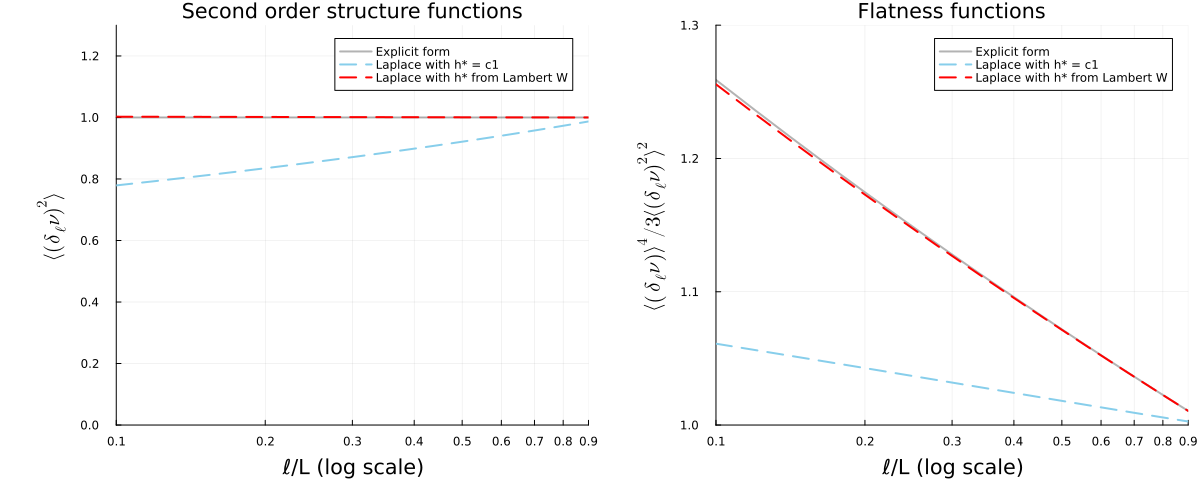

In [60]:
# Define l values
l_values = 0.1*L:0.02*L:0.9*L

# Compute S2 and Flatness for each l
S2_A_values = [S2(l) for l in l_values]
S2_B_values = [S2_Laplace(l, h_star) for l in l_values]
S2_C_values = [S2_Laplace(l, h_star2) for l in l_values]

Flatness_A_values = [S4(l)/(S2(l)^2) for l in l_values]
Flatness_B_values = [S4_Laplace(l, h_star)/(S2_Laplace(l, h_star)^2) for l in l_values]
Flatness_C_values = [S4_Laplace(l, h_star2)/(S2_Laplace(l, h_star2)^2) for l in l_values]

# Ticks for the plots
ticks = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
ticks_y1 = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0, 1.2]
tick_y2 = [1.0, 1.1, 1.2, 1.3]

# Labels
lab_A = "Explicit form"
lab_B = "Laplace with h* = c1"
lab_C = "Laplace with h* from Lambert W"

# Plot p1
p1 = plot(l_values./L, S2_A_values, label = lab_A,
          title = "Second order structure functions",
          xlabel = "ℓ/L (log scale)",
          ylabel = L"\langle (\delta_\ell \nu)^2 \rangle",
          xscale = :log10,
          xticks = (ticks, string.(ticks)),
          yticks = (ticks_y1, string.(ticks_y1)),
          xlims = (0.1, 0.9), ylims = (0, 1.3),
          lw = 2, guidefontsize = 14,
          color=:black, alpha=0.3,
          legend = :topright, legendfontsize = 8,
          left_margin = 15mm, bottom_margin = 10mm)

plot!(p1, l_values./L, S2_B_values, label = lab_B, lw = 2, color=:skyblue, ls = :dash)
plot!(p1, l_values./L, S2_C_values, label = lab_C, lw = 2, color=:red, ls = :dash)

# Plot p2
p2 = plot(l_values./L, Flatness_A_values ./ 3, label = lab_A,
          title = "Flatness functions",
          xlabel = "ℓ/L (log scale)",
          ylabel = L"\langle \left( \delta_\ell \nu \right) \rangle ^4 / 3 \langle (\delta_\ell \nu)^2 \rangle ^2",
          xscale = :log10,
          xticks = (ticks, string.(ticks)),
          yticks = (tick_y2, string.(tick_y2)),
          xlims = (0.1, 0.9), ylims = (1.0, 1.3),
          lw = 2, guidefontsize = 14,
          color=:black, alpha=0.3,
          legend = :topright, legendfontsize = 8,
          left_margin = 15mm, bottom_margin = 10mm)

plot!(p2, l_values./L, Flatness_B_values ./ 3, label = lab_B, lw = 2, color=:skyblue, ls = :dash)
plot!(p2, l_values./L, Flatness_C_values ./ 3, label = lab_C, lw = 2, color=:red, ls = :dash)

# Display
n_properties = plot(p1, p2, layout = (1, 2), size = (1200, 500))
savefig(n_properties, joinpath(@__DIR__, "..", "latex/images/normalized_figures", "n_properties.png"))

n_properties

### 5. Entropies

In [61]:
# Function to compute entropy for a given l, with h_star for Laplace approximation

function compute_entropy_for_l(p_function, l, h_star=nothing)
    # Define the integrand logic based on whether h_star (the function) is provided
    if isnothing(h_star)
        integrand = x -> begin
            p = p_function(l, x)
            val = p > 0 ? -p * log(p) : 0.0
            return isfinite(val) ? val : 0.0
        end
    else
        integrand = x -> begin
            # Here, h_star is called as a function inside the call to p_function
            p = p_function(l, x, h_star)
            val = p > 0 ? -p * log(p) : 0.0
            return isfinite(val) ? val : 0.0
        end
    end

    # Numerical integration
    entropy, err = quadgk(integrand, -Inf, Inf)
    
    return entropy
end

compute_entropy_for_l (generic function with 2 methods)

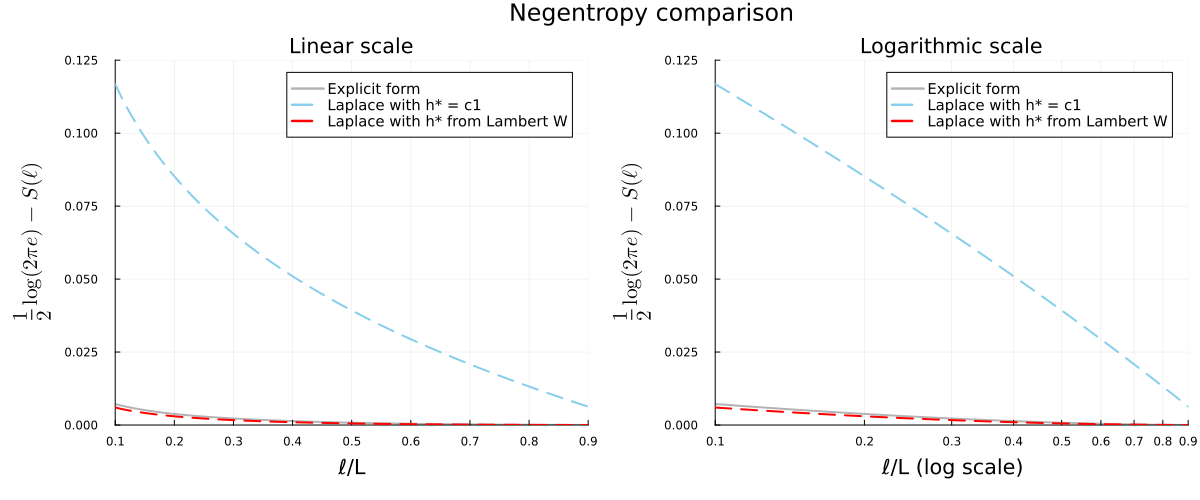

In [62]:
# Define l values
l_values = 0.1*L:0.01*L:0.9*L

# Compute S(l) for each l and each method
S_A_values = [0.5 * log(2*pi*exp(1)) - compute_entropy_for_l(compute_P_δlv_of_x,l) for l in l_values]
S_B_values = [0.5 * log(2*pi*exp(1)) - compute_entropy_for_l(compute_P_δlv_of_x_Laplace,l, h_star) for l in l_values]
S_C_values = [0.5 * log(2*pi*exp(1)) - compute_entropy_for_l(compute_P_δlv_of_x_Laplace,l, h_star2) for l in l_values]

# Ticks for the plots
ticks = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
y_ticks = [0.0, 0.025, 0.05, 0.075, 0.1, 0.125]

# Labels
label1 = "Explicit form"
label2 = "Laplace with h* = c1"
label3 = "Laplace with h* from Lambert W"

# Plot p1
p1 = plot(l_values./L, S_A_values, label = label1,
          title = "Linear scale",
          xlabel = "ℓ/L",
          ylabel = L"\frac{1}{2} \log(2\pi e) - S(\ell)",
          xlims = (0.1, 0.9),
          ylims = (0, 0.125),
          xticks = ticks,
          yticks = y_ticks,
          lw = 2,
          color=:black, alpha=0.3,
          guidefontsize = 14,
          legend = :topright,
          legendfontsize = 10,
          left_margin = 10mm,
          bottom_margin = 10mm)

plot!(p1, l_values./L, S_B_values, label = label2, lw = 2, color=:skyblue, ls=:dash)
plot!(p1, l_values./L, S_C_values, label = label3, lw = 2, color=:red, ls=:dash)

# Plot p2
p2 = plot(l_values./L, S_A_values, label = label1,
          title = "Logarithmic scale",
          xlabel = "ℓ/L (log scale)",
          ylabel = L"\frac{1}{2} \log(2\pi e) - S(\ell)",
          xscale = :log10,
          xlims = (0.1, 0.9),
          ylims = (0, 0.125),
          xticks = (ticks, string.(ticks)),
          yticks = y_ticks,
          lw = 2,
          color=:black, alpha=0.3,
          guidefontsize = 14,
          legend = :topright,
          legendfontsize = 10,
          left_margin = 10mm,
          bottom_margin = 10mm)

plot!(p2, l_values./L, S_B_values, label = label2, lw = 2, color=:skyblue, ls=:dash)
plot!(p2, l_values./L, S_C_values, label = label3, lw = 2, color=:red, ls=:dash)

# Display
n_negentropy = plot(p1, p2, layout = (1, 2), size = (1200, 500), plot_title = "Negentropy comparison", plot_titlevspan = 0.07)
savefig(n_negentropy, joinpath(@__DIR__, "..", "latex/images/normalized_figures", "n_negentropy.png"))

n_negentropy